Kernel    Acc train   Acc test
linear    0.987       0.956
poly      0.914       0.868
rbf       0.989       0.982
sigmoid   0.954       0.956


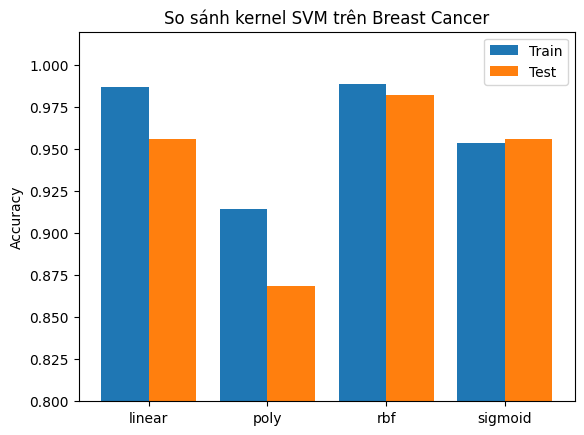

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Dùng bộ Breast Cancer giống code mẫu SVM trong đề cương
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Chuẩn hóa: SVM rất nhạy với thang đo của đặc trưng
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit chỉ trên train
X_test = scaler.transform(X_test)

# 4 kernel phổ biến của SVC:
# linear : siêu phẳng tuyến tính
# poly   : đa thức (mặc định bậc 3)
# rbf    : hàm Gauss, xử lý tốt dữ liệu phi tuyến
# sigmoid: dạng hàm tanh
kernels = ["linear", "poly", "rbf", "sigmoid"]
acc_train, acc_test = [], []

print(f"{'Kernel':<10}{'Acc train':<12}{'Acc test'}")
for kernel in kernels:
    svm = SVC(kernel=kernel, C=1, gamma="scale")
    svm.fit(X_train, y_train)
    a_tr = accuracy_score(y_train, svm.predict(X_train))
    a_te = accuracy_score(y_test, svm.predict(X_test))
    acc_train.append(a_tr)
    acc_test.append(a_te)
    print(f"{kernel:<10}{a_tr:<12.3f}{a_te:.3f}")

# Biểu đồ cột so sánh
x = np.arange(len(kernels))
plt.bar(x - 0.2, acc_train, 0.4, label="Train")
plt.bar(x + 0.2, acc_test, 0.4, label="Test")
plt.xticks(x, kernels)
plt.ylim(0.8, 1.02)
plt.ylabel("Accuracy")
plt.title("So sánh kernel SVM trên Breast Cancer")
plt.legend()
plt.show()

# NHẬN XÉT (điền theo kết quả thực tế):
# - Train cao hơn test nhiều -> dấu hiệu overfit (thường gặp ở poly).
# - Bộ này gần như tách tuyến tính nên linear và rbf thường đều tốt.

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# GridSearchCV thử TẤT CẢ tổ hợp siêu tham số trong lưới,
# với mỗi tổ hợp đánh giá bằng cross-validation (cv=5: chia train thành 5 phần,
# lần lượt dùng 1 phần để kiểm tra, 4 phần để huấn luyện), rồi chọn tổ hợp tốt nhất.
param_grid = {
    "C": [0.1, 1, 10, 100],             # mức phạt sai số: lớn -> khớp chặt, dễ overfit
    "gamma": ["scale", 0.01, 0.1, 1],   # độ "rộng" của kernel rbf: lớn -> ranh giới phức tạp
    "kernel": ["linear", "rbf"],
}
# Tổng số mô hình huấn luyện: 4 x 4 x 2 x 5 (fold) = 160

grid = GridSearchCV(SVC(), param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)   # chỉ tìm trên tập train, KHÔNG dùng tập test

print("Siêu tham số tốt nhất:", grid.best_params_)
print(f"Accuracy CV tốt nhất: {grid.best_score_:.3f}")

# best_estimator_ đã được huấn luyện lại trên toàn bộ tập train với tham số tốt nhất
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print(f"Accuracy trên tập test: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

# NHẬN XÉT:
# - GridSearchCV tự động hóa việc chọn C, gamma, kernel thay vì thử tay.
# - Chọn tham số bằng CV trên train, rồi mới đánh giá 1 lần trên test để kết quả khách quan.
# - Nhược điểm: lưới càng lớn thì càng chậm.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# ---------------------------------------------------------
# 1. Tải dữ liệu Digits: 1797 ảnh chữ số 8x8 (64 đặc trưng), nhãn 0-9
# ---------------------------------------------------------
digits = load_digits()
X, y = digits.data, digits.target
print("Kích thước X:", X.shape)

# ---------------------------------------------------------
# 2. Chuẩn hóa và chia train/test
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ---------------------------------------------------------
# 3. Huấn luyện KNN, SVM poly, SVM rbf
# ---------------------------------------------------------
models = {
    "KNN (K=3)":  KNeighborsClassifier(n_neighbors=3),
    "SVM poly":   SVC(kernel="poly", C=1, gamma="scale"),
    "SVM rbf":    SVC(kernel="rbf", C=1, gamma="scale"),
}

# ---------------------------------------------------------
# 4. So sánh độ chính xác và vẽ ma trận nhầm lẫn
# ---------------------------------------------------------
plt.figure(figsize=(18, 5))
for i, (ten, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{ten:<12}: accuracy = {acc:.4f}")

    plt.subplot(1, 3, i + 1)
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
    plt.title(f"{ten} (acc={acc:.3f})")
    plt.xlabel("Dự đoán")
    plt.ylabel("Thực tế")
plt.tight_layout()
plt.show()

# NHẬN XÉT (điền theo kết quả thực tế):
# - Đường chéo chính của ma trận nhầm lẫn là số mẫu đoán đúng; ô ngoài đường chéo là nhầm lẫn.
# - Xem cặp chữ số nào hay bị nhầm (ví dụ 8 với 1, 9 với 5) ở các ô ngoài đường chéo.
# - Thường rbf và KNN đều đạt trên 0.97; poly có thể thấp hơn chút do bị
#   ảnh hưởng bởi dữ liệu đã chuẩn hóa.